# 05. 경로별 혼잡도와 출발 시각 추천

02~04에서 '언제, 어느 방향으로 타느냐'가 혼잡도를 가장 크게 좌우한다는 것을 확인했다.
이번에는 실제 이동 경로 단위로 계산한다.

1. 역간 소요시간으로 1~8호선 노선 그래프를 만든다.
2. 출발역→도착역 경로를 따라 시각을 누적하면서, 각 구간에서 탈 열차의 혼잡도를 찾는다.
3. 출발 시각을 바꿔 가며 계산해서 **가장 덜 붐비는 출발 시각과 경로**를 추천한다.

구현은 `src/subway/route.py`에 있고, 이 노트북은 그래프를 검증하고 예시를 보여준다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

from subway.load import load_congestion, load_travel_time
from subway.clean import clean_congestion, find_structural_zeros
from subway import route
from subway.route import build_graph, CongestionLookup, candidate_paths, simulate, departure_table, recommend, fmt_time, line_sequence

sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, FIG = ROOT / "data" / "raw", ROOT / "reports" / "figures"

raw = load_congestion(RAW / "서울교통공사_지하철혼잡도정보_20260930.csv")
df = clean_congestion(raw)
travel = load_travel_time(RAW / "서울교통공사 역간거리 및 소요시간_240810.csv")
g = build_graph(travel)
lookup = CongestionLookup(df)

## 1. 그래프 검증

In [2]:
ride = [(u, v, d) for u, v, d in g.edges(data=True) if d["kind"] == "ride"]
print(f"노드(노선, 역) {g.number_of_nodes()}개, 승차 구간 {len(ride)}개, 환승 연결 {g.number_of_edges() - len(ride)}개")
print("모든 역에서 모든 역으로 갈 수 있는가:", nx.is_strongly_connected(g))

missing = [(u, v) for u, v, d in ride for h in (8.0, 18.0)
           if np.isnan(lookup.get("평일", d["line"], u[1], v[1], d["direction"], h))]
print("평일 08시·18시에 혼잡도를 찾지 못한 구간:", len(missing))

노드(노선, 역) 277개, 승차 구간 536개, 환승 연결 78개
모든 역에서 모든 역으로 갈 수 있는가: True
평일 08시·18시에 혼잡도를 찾지 못한 구간: 0


### 방향 이름 확인

소요시간 파일의 순서(정방향)가 상선인지 하선인지는 데이터에 나와 있지 않다.
**종착역에서 '하루 종일 0'인 방향은 그 역에서 더 나아가는 방향**이라는 점(01 EDA)을 이용해 확인한다.

In [3]:
zeros = find_structural_zeros(raw).query("day_type == '평일'")[["line", "station", "direction"]]
ordered = travel.sort_values("seq").groupby("line")
first, last = ordered.head(1)[["line", "station"]], ordered.tail(1)[["line", "station"]]
check = (first.merge(zeros, on=["line", "station"], how="left").set_index("line")
         .join(last.merge(zeros, on=["line", "station"], how="left").set_index("line"), lsuffix="_첫", rsuffix="_끝"))
check.columns = ["첫 역", "첫 역에서 종일 0", "마지막 역", "마지막 역에서 종일 0"]
check["가정: 정방향 / 역방향"] = [" / ".join(route.FORWARD_DIR[l]) for l in check.index]
check.fillna("-")

C:\Users\donga\AppData\Local\Temp\ipykernel_26676\1435674832.py:5: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  .join(last.merge(zeros, on=["line", "station"], how="left").set_index("line"), lsuffix="_첫", rsuffix="_끝"))


,첫 역,첫 역에서 종일 0,마지막 역,마지막 역에서 종일 0,가정: 정방향 / 역방향
line,,,,,
1,서울역,-,청량리,-,하선 / 상선
2,시청,-,까치산,내선,내선 / 외선
3,지축,-,오금,하선,하선 / 상선
4,불암산,-,남태령,-,하선 / 상선
5,방화,상선,마천,하선,하선 / 상선
6,응암,상선,신내,하선,하선 / 상선
7,장암,상선,온수,-,하선 / 상선
8,암사역사공원,-,모란,하선,하선 / 상선


- 3·5·6·8호선은 파일 마지막 역(오금·마천·신내·모란)에서 **하선**이 종일 0이다. 마지막 역에서 더 나아가는 방향이 하선이므로, 파일 순서 방향이 하선이다.
- 5·6·7호선은 첫 역(방화·응암·장암)에서 **상선**이 종일 0이다. 첫 역에서 거꾸로 가는 방향이 상선이라는 뜻이라 같은 결론이다.
- 1·4호선은 양 끝이 코레일 구간으로 이어져서 종일 0인 방향이 없다. 역번호가 파일 순서 양 끝에서 커지는 점(서울역 150 → 청량리 158, 불암산 409 → 남태령 434)을 근거로 같은 규칙을 적용했다. 다른 노선보다 근거가 약하다.
- 2호선 순환선은 지선 끝 역 까치산에서 내선이 0이라 신정지선과 본선의 파일 순서가 내선이다. 성수지선은 끝 역 신설동에서 외선이 0이라 외선이 파일 순서다(`BRANCH_FORWARD_DIR`).

In [4]:
loop = [d["cost"] for u, v, d in ride if d["line"] == 2 and d["direction"] == "내선"
        and u[1] not in {"용답", "신답", "용두", "신설동", "도림천", "양천구청", "신정네거리", "까치산"}
        and v[1] not in {"용답", "신답", "용두", "신설동", "도림천", "양천구청", "신정네거리", "까치산"}]
print(f"2호선 순환 한 바퀴: 운행시간 {sum(loop) - len(loop) * route.DWELL_MIN:.1f}분 + 정차 {len(loop)}회×{route.DWELL_MIN}분 = {sum(loop):.1f}분")

for o, d in [("연신내", "응암"), ("응암", "연신내")]:
    p = candidate_paths(g, o, d, k=1)[0]
    print(f"{o} → {d}: {' → '.join(n[1] for n in p)} ({simulate(g, lookup, p, 8.0).legs.minutes.sum():.1f}분)")

2호선 순환 한 바퀴: 운행시간 65.0분 + 정차 43회×0.5분 = 86.5분
연신내 → 응암: 연신내 → 구산 → 응암 (4.3분)
응암 → 연신내: 응암 → 역촌 → 불광 → 독바위 → 연신내 (8.5분)


- 소요시간 파일의 시간은 **정차 시간을 뺀 운행시간**이다. 역마다 30초 정차를 가정했다(`DWELL_MIN`). 2호선 한 바퀴가 약 86분이 된다.
- 6호선 응암순환은 응암→역촌→…→구산→응암 한 방향으로만 다닌다. 그래서 연신내→응암은 구산을 거쳐 2정거장이고, 응암→연신내는 역촌·불광·독바위를 거쳐 4정거장이다.
- 환승은 이동과 대기를 합쳐 4분으로 가정했다(`TRANSFER_MIN`). 실제로는 역마다 차이가 크다.

## 2. 예시: 아침 9시까지 홍대입구에 도착해야 할 때 (사당 출발)

In [5]:
am = departure_table(g, lookup, "사당", "홍대입구", start=7.0, end=8.5, step_min=10)
routes_am = am.groupby("경로").agg(노선=("노선", "first"), 환승=("환승", "first"), 소요=("소요(분)", "first"))
display(routes_am)

best = recommend(am, arrive_by=9.0)
fastest_late = am[(am.경로 == 0) & (am.도착 <= 9.0)].sort_values("출발").iloc[-1]
print(f"추천: {fmt_time(best.출발)} 출발, {best.노선}, {fmt_time(best.도착)} 도착, 평균 혼잡도 {best['평균 혼잡도']:.0f}%")
print(f"비교: 최단 경로로 가장 늦게 출발({fmt_time(fastest_late.출발)}) 하면 평균 혼잡도 {fastest_late['평균 혼잡도']:.0f}%, 최대 {fastest_late['최대 혼잡도']:.0f}%")

,노선,환승,소요
경로,,,
0,2호선,0,28.5
1,4호선 → 6호선 → 2호선,2,33.0
2,4호선 → 1호선 → 2호선,2,36.0


추천: 07:00 출발, 4호선 → 6호선 → 2호선, 07:33 도착, 평균 혼잡도 31%
비교: 최단 경로로 가장 늦게 출발(08:30) 하면 평균 혼잡도 62%, 최대 95%


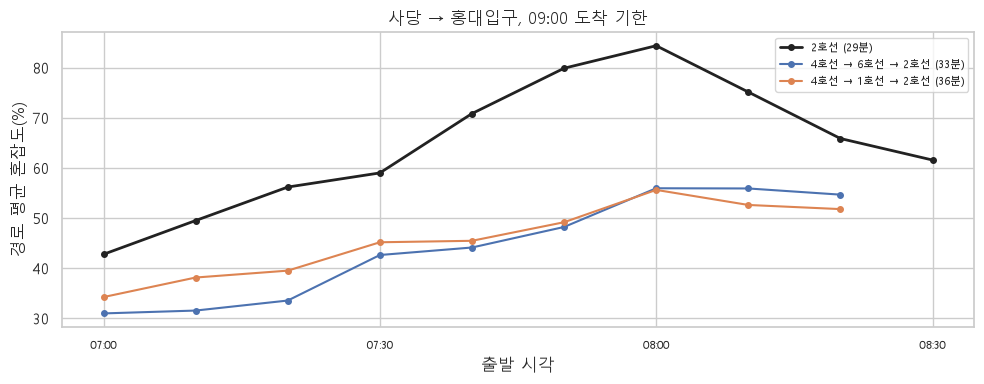

In [6]:
def plot_departures(table, title, deadline=None, ax=None):
    ax = ax or plt.gca()
    if deadline is not None:
        table = table[table.도착 <= deadline]  # 기한을 넘기는 출발 시각은 그리지 않는다
    palette = ["#222222", "#4c72b0", "#dd8452"]
    for i, (k, t) in enumerate(table.groupby("경로")):
        label = f"{t.노선.iloc[0]} ({t['소요(분)'].iloc[0]:.0f}분)"
        ax.plot(t.출발, t["평균 혼잡도"], "o-", color=palette[i % 3], lw=2 if k == 0 else 1.5, ms=4, label=label)
    ticks = sorted(table.출발.unique())[::3]
    ax.set_xticks(ticks); ax.set_xticklabels([fmt_time(h) for h in ticks], fontsize=8)
    ax.set(xlabel="출발 시각", ylabel="경로 평균 혼잡도(%)", title=title)
    ax.legend(fontsize=8)

plt.figure(figsize=(10, 4))
plot_departures(am, "사당 → 홍대입구, 09:00 도착 기한", deadline=9.0)
plt.tight_layout(); plt.show()

- 최단 경로(2호선, 28.5분)로 08:00에 타면 평균 84%, 신도림~문래 구간은 133%까지 올라간다.
- 같은 2호선이라도 07:00에 타면 평균 43%다. 4호선→6호선→2호선으로 돌아가면 4.5분 더 걸리지만 07:00 출발 기준 31%까지 내려간다.
- 9시 도착이 기한이라면, 출발을 30분~1시간 당기고 경로를 바꾸는 것만으로 체감 혼잡도가 절반 이하가 된다.

## 3. 예시: 저녁 하교 (홍대입구 → 사당)

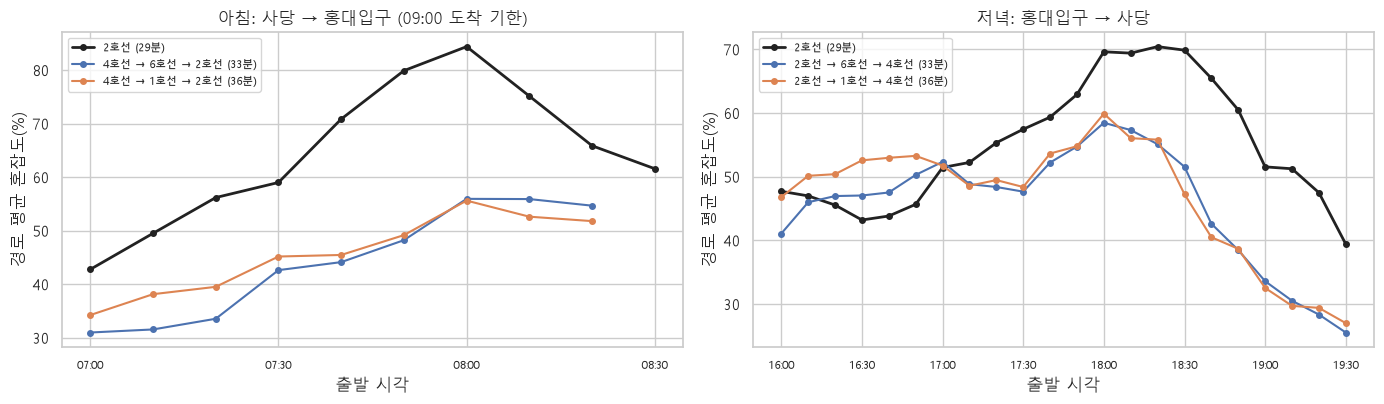

저녁 최단 경로 평균 혼잡도: 16:00 48%, 16:30 43%, 17:00 51%, 17:30 57%, 18:00 70%, 18:30 70%, 19:00 52%, 19:30 39%
저녁 추천: 19:30 출발, 2호선 → 6호선 → 4호선, 평균 혼잡도 26%


In [7]:
pm = departure_table(g, lookup, "홍대입구", "사당", start=16.0, end=19.5, step_min=10)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
plot_departures(am, "아침: 사당 → 홍대입구 (09:00 도착 기한)", deadline=9.0, ax=axes[0])
plot_departures(pm, "저녁: 홍대입구 → 사당", ax=axes[1])
plt.tight_layout(); plt.savefig(FIG / "09_route_departures.png", dpi=150); plt.show()

main_pm = pm[pm.경로 == 0].set_index("출발")["평균 혼잡도"]
print("저녁 최단 경로 평균 혼잡도: " + ", ".join(f"{fmt_time(h)} {v:.0f}%" for h, v in main_pm.iloc[::3].items()))
best_pm = recommend(pm)
print(f"저녁 추천: {fmt_time(best_pm.출발)} 출발, {best_pm.노선}, 평균 혼잡도 {best_pm['평균 혼잡도']:.0f}%")

- 저녁 최단 경로(2호선)는 16:30이 43%로 가장 낮고, 18:00~18:30에 70%로 가장 높다. 19:30이 되면 30%대로 내려간다.
- **17시 이후에는 경로 선택이 더 중요해진다.** 2호선→6호선→4호선이나 2호선→1호선→4호선으로 돌아가면 4~8분 더 걸리지만, 18:00~19:00에는 2호선보다 10~25%p 덜 붐빈다.
- 수업이 16시 전후로 끝난다면 바로 출발하는 것이 낫다. 17:30~18:30에 출발해야 한다면 우회 경로를, 늦게 출발할 수 있다면 19시 이후를 고르는 것이 좋다.

## 4. 구간별로 보기

In [8]:
p = candidate_paths(g, "사당", "홍대입구", k=1)[0]
for depart in (7.0, 8.0):
    trip = simulate(g, lookup, p, depart)
    legs = trip.legs.assign(탑승=lambda x: x.board.map(fmt_time))[["탑승", "line", "from", "to", "direction", "congestion"]]
    print(f"\n{fmt_time(depart)} 출발 → {fmt_time(trip.arrive)} 도착, 평균 {trip.mean_congestion:.0f}%, 최대 {trip.max_congestion:.0f}%")
    print(legs.to_string(index=False))


07:00 출발 → 07:29 도착, 평균 43%, 최대 58%
   탑승  line    from      to direction  congestion
07:00     2      사당     낙성대        내선        26.0
07:02     2     낙성대   서울대입구        내선        26.5
07:04     2   서울대입구      봉천        내선        26.9
07:06     2      봉천      신림        내선        30.0
07:08     2      신림     신대방        내선        30.4
07:11     2     신대방 구로디지털단지        내선        36.4
07:13     2 구로디지털단지      대림        내선        44.2
07:14     2      대림     신도림        내선        50.2
07:18     2     신도림      문래        내선        58.3
07:20     2      문래   영등포구청        내선        55.3
07:22     2   영등포구청      당산        내선        56.3
07:24     2      당산      합정        내선        55.7
07:27     2      합정    홍대입구        내선        52.1

08:00 출발 → 08:28 도착, 평균 84%, 최대 133%
   탑승  line    from      to direction  congestion
08:00     2      사당     낙성대        내선        41.3
08:02     2     낙성대   서울대입구        내선        42.0
08:04     2   서울대입구      봉천        내선        43.7
08:06     2      봉천      

## 5. 구간마다 5분으로 어림하면

In [9]:
def simulate_fixed(path, depart, minutes_per_stop=5.0):
    t, vals = depart, []
    for u, v in zip(path, path[1:]):
        e = g.edges[u, v]
        if e["kind"] == "ride":
            vals.append(lookup.get("평일", e["line"], u[1], v[1], e["direction"], t))
            t += minutes_per_stop / 60
        else:
            t += e["minutes"] / 60
    return t, np.nanmean(vals)

rows = []
for o, d in [("사당", "홍대입구"), ("노원", "안암"), ("잠실", "신촌"), ("까치산", "신설동")]:
    p = candidate_paths(g, o, d, k=1)[0]
    real = simulate(g, lookup, p, 8.0)
    t5, c5 = simulate_fixed(p, 8.0)
    rows.append({"경로": f"{o} → {d}", "정거장 수": len(real.legs), "소요(실제 기준, 분)": (real.arrive - 8) * 60,
                 "소요(5분 어림, 분)": (t5 - 8) * 60, "평균 혼잡도(실제 기준)": real.legs.congestion.mean(), "평균 혼잡도(5분 어림)": c5})
pd.DataFrame(rows).round(1)

,경로,정거장 수,"소요(실제 기준, 분)","소요(5분 어림, 분)",평균 혼잡도(실제 기준),평균 혼잡도(5분 어림)
0,사당 → 홍대입구,13,28.5,65.0,83.2,65.4
1,노원 → 안암,10,21.7,54.0,72.9,67.6
2,잠실 → 신촌,19,35.0,95.0,60.9,46.6
3,까치산 → 신설동,20,41.8,104.0,94.4,72.5


구간마다 5분으로 어림하면 소요시간이 실제의 2~3배로 늘어난다. 시각이 뒤로 밀리면서 **실제로 탈 열차가 아닌 30분~1시간 뒤 열차의 혼잡도**를 보게 된다.
08시에 출발하는 경우라면 이미 피크가 지난 시각의 값을 읽어서 혼잡도를 낮게 잡는다. 표준 운행시간을 쓰는 것이 결과의 정확도에 직접 영향을 준다.

## 정리

- 역간 소요시간으로 1~8호선 277개 (노선, 역)과 환승을 잇는 그래프를 만들었다. 지선 분기점, 6호선 단방향 순환, 방향 이름을 데이터로 확인했다.
- 출발 시각과 경로를 바꿔 가며 경로 평균 혼잡도를 계산하면, 같은 도착 기한 안에서 **훨씬 덜 붐비는 선택지**를 찾을 수 있다.
- 이 계산을 웹앱에 그대로 쓴다: 출발역·도착역·요일·도착 기한을 넣으면 위 그래프와 추천을 보여준다.

**가정과 한계**
- 정차 30초, 환승 4분은 가정값이다. 첫 열차를 기다리는 시간은 넣지 않았다.
- 혼잡도는 출발역에서 그 방향으로 떠나는 열차들의 30분 평균이다. 내가 탈 열차 한 대의 혼잡도와는 다를 수 있다.
- 1~8호선(서울교통공사 구간)만 다룬다. 9호선·신분당선 등을 거치는 더 빠른 경로는 고려하지 않는다.
- 성수·신도림·강동·응암처럼 한 역에 행이 여러 개인 경우 구간별로 어느 행을 쓸지 `EDGE_CODE`에 지정했다. 성수(211) 외선은 원자료가 비어 있어 역번호 9001(성수E) 행으로 대신했다.